# Diferenciando Trap e Boombap com Modelagem Clássica de IA

### Uma Análise de Gêneros Musicais usando Aprendizado de Máquina

In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


## Coleta de Letras para Classificação

Coleta até `ALVO` (400) letras de **Trap BR** e 400 de **Hip Hop BR (boom bap)** pela API pública do [LRCLIB](https://lrclib.net), buscando por uma lista de artistas de cada gênero. O rótulo (`genero`) vem do artista.

Cada artista contribui com no máximo `MAX_POR_ARTISTA` músicas, e letras repetidas (mesma música em vários álbuns) são descartadas. O resultado é um único arquivo, `dataset.csv`, com as colunas `artista`, `titulo`, `genero` e `letra`.

In [127]:
import os
import re
import ssl
import time
import unicodedata
import pandas as pd
import requests
from requests.adapters import HTTPAdapter

SAIDA = "dataset.csv"
ALVO = 400            # músicas por gênero
MAX_POR_ARTISTA = 20  # evita que poucos artistas dominem o dataset
PAUSA = 1             # segundos entre requisições, para não sobrecarregar a API
HEADERS = {"User-Agent": "classificador-trap-rap (projeto pessoal)"}
CERTIFICADOS = "certificados.pem"  # certificados normais + o do firewall da rede da faculdade

# O gênero vem do artista. Se algum gênero não chegar no ALVO, adicione mais nomes.
# "Borges" e "Rapadura" foram retirados: a busca trazia homônimos (ver Tratamento de Dados).
ARTISTAS = {
    "trap": [
        "Matuê", "Teto", "Wiu", "Veigh", "Orochi", "Kayblack", "Chefin", "Sidoka",
        "Yunk Vino", "Brandão85", "Kyan", "Recayd Mob", "Tz da Coronel",
        "Caio Luccas", "Oruam", "L7nnon", "Mc Igu", "Xamã", "Duzz",
        "Raffa Moreira", "Nagalli", "Ryu, the Runner", "Jovem Dex", "BIN",
        "Meno Tody", "Phl Notunrboy", "MC Cabelinho", "Derek", "Tasha e Tracie",
        "LPT Zlatan", "Alee", "Duquesa",
    ],
    "hiphop": [
        "Racionais MC's", "Sabotage", "Emicida", "Criolo", "Rashid", "Projota",
        "Rincon Sapiência", "BK", "Kamau", "Marcelo D2", "Facção Central", "SNJ",
        "RZO", "Thaíde", "MV Bill", "Inquérito", "GOG", "Dexter", "Rael",
        "Ndee Naldinho", "Síntese", "Coruja BC1", "Don L", "Black Alien", "Djonga",
        "Sant", "Froid", "Haikaiss", "Ogi", "Parteum",
        "Z'África Brasil", "Consciência Humana", "509-E", "Rappin' Hood",
    ],
}


class AdapterRedeComFirewall(HTTPAdapter):
    """Confia no certificado do firewall da rede. Desliga só a checagem estrita do
    Python 3.13+ (o certificado do firewall não tem o campo Authority Key Identifier);
    a verificação da cadeia e do domínio continua ativa."""
    def init_poolmanager(self, *args, **kwargs):
        ctx = ssl.create_default_context(cafile=CERTIFICADOS)
        ctx.verify_flags &= ~ssl.VERIFY_X509_STRICT
        kwargs["ssl_context"] = ctx
        super().init_poolmanager(*args, **kwargs)


sessao = requests.Session()
sessao.headers.update(HEADERS)
if os.path.exists(CERTIFICADOS):  # fora da rede da faculdade o arquivo não é necessário
    sessao.mount("https://", AdapterRedeComFirewall())


def normalizar(s: str) -> str:
    """minúsculo, sem acento e sem pontuação: 'Racionais MC's' -> 'racionais mcs'"""
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9 ]", "", s.lower())


def buscar_artista(artista: str, tentativas: int = 5, params: dict | None = None) -> list:
    """Pesquisa no LRCLIB (por padrão, pelo nome do artista), tentando de novo se a API estiver sobrecarregada."""
    for t in range(tentativas):
        try:
            r = sessao.get("https://lrclib.net/api/search", params=params or {"q": artista}, timeout=15)
            if r.status_code in (429, 503):  # API sobrecarregada: espera e tenta de novo
                time.sleep(2 ** t)
                continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException as e:
            print(f"  erro buscando {artista}: {e}")
            return []
    print(f"  {artista}: API indisponível após {tentativas} tentativas")
    return []


# Carrega o que já foi coletado: artista que já está no dataset não é buscado de novo
try:
    linhas = pd.read_csv(SAIDA).to_dict("records")
except (FileNotFoundError, pd.errors.EmptyDataError):
    linhas = []
ja_coletados = {l["artista"] for l in linhas}
vistas = {normalizar(l["letra"])[:200] for l in linhas}  # a mesma música aparece em vários álbuns
print(f"{len(linhas)} letras já estavam em {SAIDA}\n")

for genero, artistas in ARTISTAS.items():
    total = sum(l["genero"] == genero for l in linhas)
    for artista in artistas:
        if total >= ALVO:
            break
        if artista in ja_coletados:
            print(f"[{genero}] {artista}: já está no dataset, pulando")
            continue
        # só aceita resultados em que o artista aparece de fato no campo artistName
        padrao = re.compile(rf"\b{re.escape(normalizar(artista))}\b")
        n = 0
        for item in buscar_artista(artista):
            letra = item.get("plainLyrics")
            if not letra or not padrao.search(normalizar(item.get("artistName") or "")):
                continue
            chave = normalizar(letra)[:200]
            if chave in vistas:
                continue
            vistas.add(chave)
            linhas.append({"artista": artista, "titulo": item["trackName"],
                           "genero": genero, "letra": letra})
            n += 1
            total += 1
            if n >= MAX_POR_ARTISTA or total >= ALVO:
                break
        if n:  # salva a cada artista: se parar no meio, nada se perde
            pd.DataFrame(linhas).to_csv(SAIDA, index=False)
        print(f"[{genero}] {artista}: {n} músicas novas (total {total})")
        time.sleep(PAUSA)

df = pd.DataFrame(linhas)
print(f"\n{len(df)} letras em {SAIDA}")
if not df.empty:
    print(df["genero"].value_counts().to_string())


800 letras já estavam em dataset.csv


800 letras em dataset.csv
genero
trap      400
hiphop    400


### Verificando o Dataset

Execute a célula acima para coletar as letras. Depois, confira o `dataset.csv` gerado abaixo.

In [128]:
df_dataset = pd.read_csv("dataset.csv")
display(df_dataset.head())
print(df_dataset["genero"].value_counts().to_string())
print(f"\n{df_dataset['artista'].nunique()} artistas diferentes")

,artista,titulo,genero,letra
0,Matuê,Matuê - Crack com Mussilon,trap,Assim que o dia amanheceu\nLá no mar alto da p...
1,Matuê,Matuê - Quer Voar,trap,"Palaze, what you cookin'? (What you cookin'?)\..."
2,Matuê,Matuê - Máquina do Tempo,trap,"Yeah, yeah, yeah, yeah, yeah\nYeah, yeah, yeah..."
3,Matuê,Bang Bang (feat. Matuê),trap,"Bang, bang\nNão tô de papo, ninguém vai me peg..."
4,Matuê,Banco,trap,"Ela me olha e vê um banco, um banco\nTijolão d..."


genero
trap      400
hiphop    400

61 artistas diferentes


## Análise Descritiva do Dataset

Antes de tratar os dados, medimos o que temos: tamanho e balanceamento das classes, tamanho das letras, riqueza de vocabulário e problemas de qualidade que o próximo capítulo (tratamento) vai precisar resolver.

### Visão geral

In [129]:
df = pd.read_csv("dataset.csv")
print(f"{df.shape[0]} músicas x {df.shape[1]} colunas")
print("\nValores nulos por coluna:")
print(df.isna().sum().to_string())
print(f"\nLetras duplicadas: {df['letra'].duplicated().sum()}")
print(f"Títulos repetidos (ignorando maiúsculas): {df['titulo'].str.lower().duplicated().sum()}")

resumo = df.groupby("genero").agg(musicas=("letra", "size"), artistas=("artista", "nunique"))
resumo["musicas_por_artista"] = (resumo["musicas"] / resumo["artistas"]).round(1)
resumo

800 músicas x 4 colunas

Valores nulos por coluna:
artista    0
titulo     0
genero     0
letra      0

Letras duplicadas: 0
Títulos repetidos (ignorando maiúsculas): 9


,musicas,artistas,musicas_por_artista
genero,,,
hiphop,400,33,12.1
trap,400,28,14.3


### Tamanho e vocabulário das letras

- **palavras / linhas / caracteres**: tamanho da letra.
- **palavras_unicas**: quantas palavras diferentes a letra usa.
- **diversidade_lexical**: palavras únicas ÷ total de palavras (1 = nenhuma palavra repetida). Cai naturalmente em letras mais longas, então compare com cuidado.

In [130]:
tokens = df["letra"].str.lower().str.findall(r"\w+")
df["caracteres"] = df["letra"].str.len()
df["palavras"] = tokens.str.len()
df["linhas"] = df["letra"].str.count("\n") + 1
df["palavras_unicas"] = tokens.apply(lambda t: len(set(t)))
df["diversidade_lexical"] = df["palavras_unicas"] / df["palavras"]

METRICAS = ["caracteres", "palavras", "linhas", "palavras_unicas", "diversidade_lexical"]
df.groupby("genero")[METRICAS].describe().T.round(2)

genero                      hiphop     trap
caracteres          count   400.00   400.00
                    mean   2704.62  1930.64
                    std    1179.65   644.28
                    min     157.00    75.00
                    25%    1935.25  1509.75
                    50%    2634.00  1941.50
                    75%    3354.75  2336.25
                    max    7488.00  4438.00
palavras            count   400.00   400.00
                    mean    520.43   378.62
                    std     222.40   130.18
                    min      26.00    18.00
                    25%     374.25   298.75
                    50%     504.50   382.00
                    75%     650.00   462.00
                    max    1441.00   852.00
linhas              count   400.00   400.00
                    mean     85.82    66.76
                    std      37.13    23.57
                    min       1.00     2.00
                    25%      60.00    51.00
                    50%      83.00    67.00
                    75%     108.25    80.00
                    max     248.00   170.00
palavras_unicas     count   400.00   400.00
                    mean    235.58   160.71
                    std     101.57    56.05
                    min      23.00    16.00
                    25%     174.75   125.00
                    50%     230.50   161.00
                    75%     302.50   196.00
                    max     625.00   335.00
diversidade_lexical count   400.00   400.00
                    mean      0.46     0.44
                    std       0.11     0.11
                    min       0.10     0.18
                    25%       0.40     0.37
                    50%       0.47     0.43
                    75%       0.53     0.49
                    max       0.96     0.97

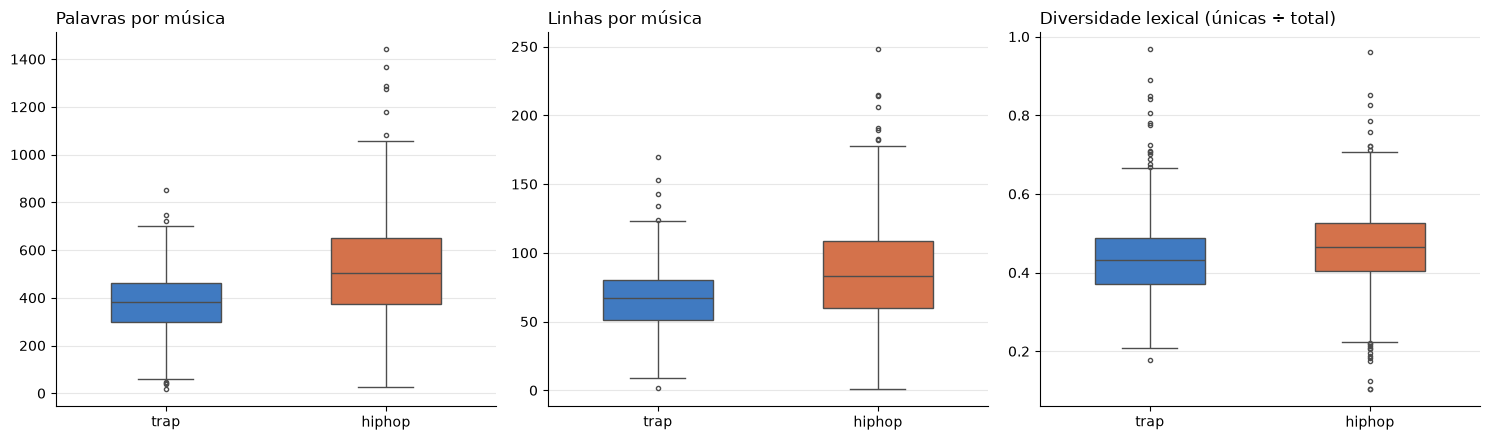

In [131]:
CORES = {"trap": "#2a78d6", "hiphop": "#eb6834"}  # paleta validada para daltonismo

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
graficos = [("palavras", "Palavras por música"),
            ("linhas", "Linhas por música"),
            ("diversidade_lexical", "Diversidade lexical (únicas ÷ total)")]
for ax, (coluna, titulo) in zip(axes, graficos):
    sns.boxplot(data=df, x="genero", y=coluna, hue="genero", palette=CORES,
                width=0.5, linewidth=1, fliersize=3, legend=False, ax=ax)
    ax.set_title(titulo, loc="left")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(axis="y", alpha=0.3)
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### Músicas por artista

O `MAX_POR_ARTISTA` limita quanto cada artista pesa no dataset. Artistas com poucas músicas não têm muitas letras no LRCLIB (ou tiveram músicas descartadas como repetidas).

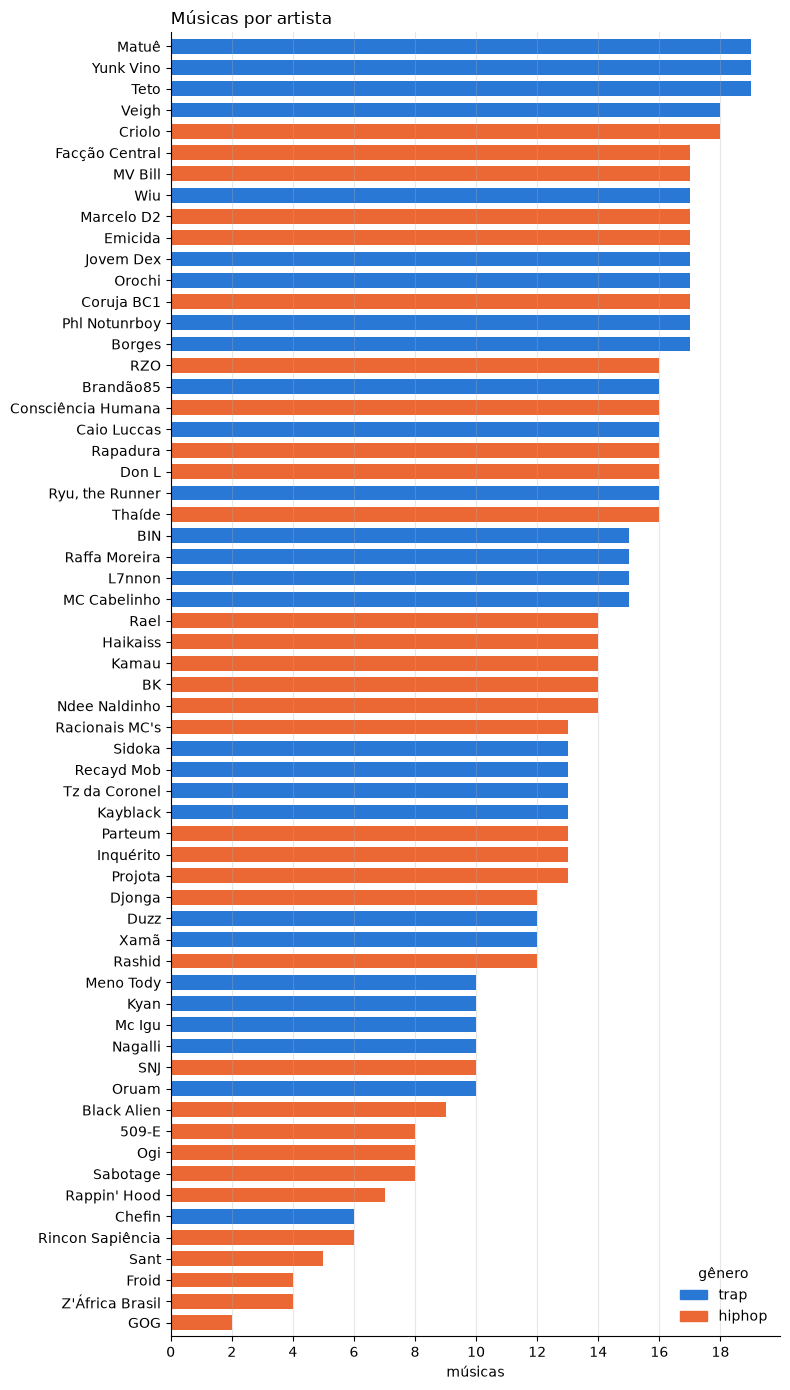

In [132]:
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

por_artista = (df.groupby(["artista", "genero"]).size()
                 .reset_index(name="musicas").sort_values("musicas"))

fig, ax = plt.subplots(figsize=(8, 14))
ax.barh(por_artista["artista"], por_artista["musicas"],
        color=por_artista["genero"].map(CORES), height=0.7)
ax.legend(handles=[Patch(color=c, label=g) for g, c in CORES.items()],
          title="gênero", loc="lower right", frameon=False)
ax.set_title("Músicas por artista", loc="left")
ax.set_xlabel("músicas")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.margins(y=0.005)
ax.grid(axis="x", alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### Palavras mais frequentes

Contagem bruta, sem nenhum tratamento. Palavras como "que", "de" e "eu" (stopwords) dominam o topo e dizem pouco sobre o gênero, e é por isso que o capítulo de tratamento remove essas palavras.

In [133]:
from collections import Counter

top = {}
for genero, grupo in df.groupby("genero"):
    contagem = Counter(w for t in tokens[grupo.index] for w in t)
    print(f"{genero}: vocabulário de {len(contagem)} palavras diferentes")
    top[genero] = [f"{w} ({n})" for w, n in contagem.most_common(20)]
pd.DataFrame(top, index=range(1, 21))

hiphop: vocabulário de 18464 palavras diferentes
trap: vocabulário de 11962 palavras diferentes


,hiphop,trap
1,que (5831),eu (4727)
2,o (5371),que (3972)
3,a (5115),o (3095)
4,é (4949),de (2973)
5,de (4590),não (2810)
6,e (4318),a (2536)
7,não (4254),é (2504)
8,eu (3697),e (2350)
9,pra (2560),me (1930)
10,se (2352),no (1776)


### Problemas de qualidade (para o capítulo de tratamento)

A busca no LRCLIB é por nome, então artistas homônimos entram no dataset: "Teto" trouxe músicas da Kasane Teto (vocaloid japonesa), "Rashid" e "BIN" trouxeram músicas em árabe e indonésio, "Sabotage" trouxe Hippie Sabotage, etc.

Para detectar isso medimos a proporção de palavras muito comuns do português em cada letra. Letras em PT ficam em torno de 30%; bem abaixo disso quase sempre é outro idioma ou outro artista.

In [134]:
PT_COMUNS = {"que", "de", "o", "a", "e", "não", "nao", "eu", "é", "do", "da", "pra", "me",
             "um", "na", "no", "se", "com", "você", "tu", "mas", "os", "as", "meu", "minha",
             "tá", "to", "tô", "isso", "quem", "mano"}
LIMITE_PT = 0.08  # heurística: abaixo de 8% de palavras comuns do PT, a letra é suspeita

df["proporcao_pt"] = tokens.apply(lambda t: sum(w in PT_COMUNS for w in t) / max(len(t), 1))
suspeitas = df[df["proporcao_pt"] < LIMITE_PT]
print(f"{len(suspeitas)} letras ({len(suspeitas) / len(df):.1%}) quase sem português, por artista:")
display(suspeitas.groupby(["genero", "artista"]).size().sort_values(ascending=False).rename("musicas"))

NUMERO_FAIXA = r"^\d+\.\s"
FEAT = r"\bfeat\.|\bft\."
print(f"Títulos com número de faixa ('3. VEIGH - ...'): {df['titulo'].str.contains(NUMERO_FAIXA).sum()}")
print(f"Títulos com o artista junto ('Matuê - ...'): {df['titulo'].str.contains(' - ').sum()}")
print(f"Títulos com feat./ft.: {df['titulo'].str.contains(FEAT, case=False).sum()}")
print(f"Letras com marcações tipo [Refrão]: {df['letra'].str.contains(r'\[').sum()}")
print(f"Letras muito curtas (< 50 palavras): {(df['palavras'] < 50).sum()}")

48 letras (6.0%) quase sem português, por artista:


genero  artista        
hiphop  Rashid             10
trap    Teto               10
        BIN                 9
hiphop  Ogi                 6
        BK                  3
        Kamau               2
        Rael                2
        Sabotage            2
trap    Kyan                2
        Matuê               1
        Ryu, the Runner     1
Name: musicas, dtype: int64

Títulos com número de faixa ('3. VEIGH - ...'): 32
Títulos com o artista junto ('Matuê - ...'): 171
Títulos com feat./ft.: 125
Letras com marcações tipo [Refrão]: 6
Letras muito curtas (< 50 palavras): 6


## Tratamento de Dados

Neste capítulo:
1. removemos as músicas que não são dos artistas brasileiros (homônimos estrangeiros e em português);
2. limpamos títulos e letras;
3. enriquecemos a base com novas variáveis;
4. geramos embeddings de título e letra;
5. olhamos os resultados em gráficos e clusters.

### 1. Removendo músicas que não são brasileiras

A busca por nome trouxe homônimos: Kasane Teto (vocaloid japonesa), cantores indianos e árabes chamados Rashid, a banda indonésia BIN, rappers turcos e búlgaros chamados Ogi, e por aí vai. Também vieram letras cadastradas erradas no LRCLIB (em "Curtir na Moral", do Thaíde, a letra é da Britney Spears).

**Por que não detectar o idioma da letra inteira:** música brasileira mistura português com inglês e às vezes abre com trechos em outra língua. "Apocalipse 1: 18-19", do Ryu, the Runner, começa com uma citação bíblica em grego. Se olharmos a letra inteira, o idioma dominante engana.

**Critério:** detectamos o idioma **linha por linha** e medimos a proporção de linhas em português. Os homônimos têm 0% de linhas em PT; as músicas brasileiras misturadas começam em ~27%. O corte em 10% fica no meio desse vão.

Efeito colateral: músicas de artistas brasileiros cantadas 100% em inglês também saem. Como o modelo vai aprender com letras em português, elas seriam ruído.

**Homônimos em português:** o filtro de idioma não pega artistas brasileiros com o mesmo nome. A análise de erros (mais adiante) mostrou dois casos, que saem inteiros:
- **Rapadura:** 15 das 16 músicas eram da banda de forró *Caviar com Rapadura*;
- **Borges:** a maioria era do Lô Borges e do Márcio Borges (MPB) e do Leandro Borges (gospel), não do Borges do trap.

Os dois também saíram da lista `ARTISTAS` da coleta.

In [135]:
from langdetect import DetectorFactory, LangDetectException, detect

DetectorFactory.seed = 0  # o langdetect é aleatório; a semente deixa o resultado reproduzível
MIN_PALAVRAS_LINHA = 4    # linhas curtas ("yeah, yeah") não dão para identificar o idioma
MIN_LINHAS_PT = 0.10      # homônimos: 0% de linhas em PT; brasileiras misturadas: 27% ou mais


def proporcao_linhas_pt(letra: str) -> float:
    linhas = {l.strip() for l in letra.splitlines() if len(l.split()) >= MIN_PALAVRAS_LINHA}  # refrão conta uma vez
    if not linhas:
        return 0.0
    em_pt = 0
    for linha in linhas:
        try:
            em_pt += detect(linha) == "pt"
        except LangDetectException:
            pass
    return em_pt / len(linhas)


# Homônimos em português, achados na análise de erros (o filtro de idioma não pega):
# "Rapadura" trouxe a banda de forró Caviar com Rapadura; "Borges" trouxe Lô e Márcio Borges (MPB)
# e Leandro Borges (gospel). Saem inteiros: não dá para separar o Borges do trap dos outros.
ARTISTAS_HOMONIMOS = {"Rapadura", "Borges"}

df["linhas_pt"] = df["letra"].apply(proporcao_linhas_pt)  # leva ~1 minuto
tem_pt = df["linhas_pt"] >= MIN_LINHAS_PT
homonimo = df["artista"].isin(ARTISTAS_HOMONIMOS)
removidas = df[~tem_pt | homonimo]
df_tratado = df.loc[tem_pt & ~homonimo, ["artista", "titulo", "genero", "letra"]].copy()

print(f"{(~tem_pt).sum()} músicas sem português + {(tem_pt & homonimo).sum()} de homônimos em português "
      f"({', '.join(sorted(ARTISTAS_HOMONIMOS))}) = {len(removidas)} removidas, {len(df_tratado)} mantidas\n")
print(df_tratado["genero"].value_counts().to_string())
display(removidas.groupby(["genero", "artista"]).size().sort_values(ascending=False).rename("removidas"))

58 músicas sem português + 32 de homônimos em português (Borges, Rapadura) = 90 removidas, 710 mantidas

genero
trap      359
hiphop    351


genero  artista      
trap    Borges           17
hiphop  Rapadura         16
        Rashid           11
trap    Teto             11
        BIN               9
hiphop  Ogi               8
        BK                5
        Rael              3
        Kamau             2
        Sabotage          2
trap    Kyan              2
hiphop  Rappin' Hood      1
        Thaíde            1
trap    Matuê             1
        Raffa Moreira     1
Name: removidas, dtype: int64

In [136]:
# Lista completa do que saiu, para conferir
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 60):
    display(removidas[["genero", "artista", "titulo", "linhas_pt"]].sort_values(["genero", "artista"]))  # linhas_pt >= 0.10 = homônimo em português

,genero,artista,titulo,linhas_pt
488,hiphop,BK,BK - ICY (Official Music Video),0.029412
490,hiphop,BK,BK - KIRPANA (Official Video) Latest Punjabi Songs 2023,0.000000
491,hiphop,BK,BK - Aaja Billo (Official Video 4K) New Punjabi Songs 20...,0.000000
498,hiphop,BK,College,0.000000
500,hiphop,BK,Sunni,0.000000
510,hiphop,Kamau,B4 EVERYTHING HAPPENED,0.000000
511,hiphop,Kamau,FALLING DOWN,0.000000
744,hiphop,Ogi,"OGI X POIZI - SENI BIRŞEY SANDIM (PROD BY. SNOW,BERKAY K...",0.000000
745,hiphop,Ogi,Чернова (ft. Дичо),0.000000
746,hiphop,Ogi,Това е обир (ft. Geoff Lagadec),0.000000


### 2. Limpeza de título e letra

- **Título**: tiramos o número da faixa ("3. VEIGH - MANDRAKA"), o nome do artista no começo, e tudo que está entre parênteses ou colchetes ("(feat. ...)", "(Official Video)", "(Deluxe)"), além de "feat."/"ft." soltos.
- **Letra**: tiramos marcações como `[Refrão]` e `[Verso 1: ...]`, que não fazem parte do que é cantado.

A letra **não** perde stopwords nem pontuação para o embedding: o modelo usa o contexto da frase inteira, e tirar palavras piora a representação. Stopwords só saem na contagem de palavras mais frequentes, mais abaixo.

In [137]:
NUMERO_FAIXA = r"^\d+\.\s*"
ENTRE_PARENTESES = r"\s*[\(\[][^\)\]]*[\)\]]"
FEAT_SOLTO = r"\s*\(?\s*\b(feat|ft)\b\.?.*$"  # também pega "(feat. X" sem fechar
MARCACAO = r"\[[^\]]*\]"                      # [Refrão], [Verso 1: MC ...]
ARTISTAS_CONHECIDOS = [normalizar(a) for lista in ARTISTAS.values() for a in lista]


def comeca_com_artista(trecho: str) -> bool:
    trecho = normalizar(trecho)
    return any(re.search(rf"\b{re.escape(a)}\b", trecho) for a in ARTISTAS_CONHECIDOS)


def limpar_titulo(titulo: str) -> str:
    t = re.sub(NUMERO_FAIXA, "", titulo)
    t = re.sub(ENTRE_PARENTESES, "", t)
    t = re.sub(FEAT_SOLTO, "", t, flags=re.IGNORECASE)
    partes = t.split(" - ")
    if len(partes) > 1 and comeca_com_artista(partes[0]):  # "Matuê - Quer Voar" -> "Quer Voar"
        t = " - ".join(partes[1:])
    return t.strip(" -") or titulo  # se sobrar nada, fica o original


df_tratado["titulo_limpo"] = df_tratado["titulo"].apply(limpar_titulo)
df_tratado["letra_limpa"] = df_tratado["letra"].str.replace(MARCACAO, "", regex=True).str.strip()

mudou = df_tratado[df_tratado["titulo"] != df_tratado["titulo_limpo"]]
print(f"{len(mudou)} títulos limpos. Exemplos:")
mudou[["titulo", "titulo_limpo"]].sample(15, random_state=1)

289 títulos limpos. Exemplos:


,titulo,titulo_limpo
282,Kurt Cobain (Acústico),Kurt Cobain
691,Black Alien - Como Eu Te Quero,Como Eu Te Quero
536,Facção Central - Estrada da dor 666,Estrada da dor 666
127,11 - Yunk Vino - Campari (Prod. 808 Luke) [Viz...,11 - Yunk Vino - Campari
221,L7NNON - Da Boca (prod. Papatinho),Da Boca
65,4. VEIGH - Artista Genérico (Eu Venci o Mundo),Artista Genérico
190,Tz da Coronel - Nota Dó ft. Kawe & Vulgo FK (P...,Nota Dó
425,Triunfo (2022),Triunfo
184,Tz da Coronel - Cheiro de Sexo (Prod. meLLo),Cheiro de Sexo
505,Tambor (feat. Rincon Sapiência & Thalma de Fre...,Tambor


### 3. Enriquecendo a base

Novas variáveis por música:
- **qtd_linhas**: linhas não vazias da letra;
- **qtd_palavras**: palavras (só letras, sem números);
- **qtd_estrangeiras** e **pct_estrangeiras**: palavras estrangeiras e quanto elas representam da letra.

**Como decidimos se uma palavra é estrangeira:** usamos o `wordfreq`, que tem a frequência de cada palavra em vários idiomas medida em textos reais, na escala *zipf* (log10; uma unidade = 10× mais comum). Uma palavra é estrangeira quando é comum em inglês (zipf ≥ 3) e bem mais comum em inglês do que em português (diferença ≥ 0,75, ou seja, ~5,6× mais comum). Isso pega "yeah", "baby", "bitch", "gang", "money", "drip" e deixa "mano", "vida" e "quebrada" como português.

Só comparamos com o inglês: é de onde vêm praticamente todos os empréstimos do rap/trap BR, e incluir o espanhol fazia gírias como "manos" e "memo" contarem como estrangeiras. Palavras que também são português ficam numa lista de exceções: "to" (tô sem acento), "for" (se for), "so" (só), "grade", "come", "age".

In [138]:
import functools
from wordfreq import zipf_frequency

PALAVRA = r"[^\W\d_]+"  # só letras
MIN_ZIPF_EN = 3.0       # a palavra precisa ser comum em inglês
MARGEM_EN = 0.75        # ~5,6x mais comum em inglês que em português
NAO_ESTRANGEIRAS = {  # existem em português (muitas vezes sem acento), gírias e interjeições
    "to", "for", "so", "grade", "come", "age", "memo", "manos", "ha", "ay", "ahn",
}


@functools.lru_cache(maxsize=None)
def estrangeira(palavra: str) -> bool:
    if palavra in NAO_ESTRANGEIRAS:
        return False
    en = zipf_frequency(palavra, "en")
    return en >= MIN_ZIPF_EN and en - zipf_frequency(palavra, "pt") >= MARGEM_EN


palavras = df_tratado["letra_limpa"].str.lower().str.findall(PALAVRA)
df_tratado["qtd_linhas"] = df_tratado["letra_limpa"].apply(lambda t: sum(bool(l.strip()) for l in t.splitlines()))
df_tratado["qtd_palavras"] = palavras.str.len()
df_tratado["qtd_estrangeiras"] = palavras.apply(lambda ps: sum(map(estrangeira, ps)))
df_tratado["pct_estrangeiras"] = df_tratado["qtd_estrangeiras"] / df_tratado["qtd_palavras"]

NOVAS = ["qtd_linhas", "qtd_palavras", "qtd_estrangeiras", "pct_estrangeiras"]
df_tratado.groupby("genero")[NOVAS].describe().T.round(2)

genero                   hiphop    trap
qtd_linhas       count   351.00  359.00
                 mean     79.67   58.65
                 std      31.03   18.10
                 min       1.00    2.00
                 25%      58.00   46.00
                 50%      78.00   58.00
                 75%      99.00   69.50
                 max     203.00  137.00
qtd_palavras     count   351.00  359.00
                 mean    546.66  393.48
                 std     212.15  114.27
                 min     104.00   18.00
                 25%     400.00  318.00
                 50%     523.00  389.00
                 75%     658.00  464.00
                 max    1434.00  852.00
qtd_estrangeiras count   351.00  359.00
                 mean      6.02   23.04
                 std      17.90   34.59
                 min       0.00    0.00
                 25%       0.00    4.00
                 50%       2.00   11.00
                 75%       5.00   29.50
                 max     183.00  338.00
pct_estrangeiras count   351.00  359.00
                 mean      0.01    0.06
                 std       0.04    0.08
                 min       0.00    0.00
                 25%       0.00    0.01
                 50%       0.00    0.03
                 75%       0.01    0.07
                 max       0.48    0.67

### 4. Embeddings de título e letra

**Modelo: [`Qwen/Qwen3-Embedding-0.6B`](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B)**, rodando localmente (grátis, sem API key):

- **Letra inteira, sem corte.** As letras têm em média ~780 tokens e a maior tem ~2.500. Ele aceita 32 mil tokens. Os modelos multilíngues mais usados (`paraphrase-multilingual-*`, `multilingual-e5`) param em 128–512 tokens e jogariam fora a maior parte da letra (só leriam o primeiro verso).
- **Multilíngue de verdade** (100+ idiomas): entende português, as gírias e o inglês misturado do trap no mesmo espaço.
- **Qualidade:** no benchmark multilíngue MMTEB (model card), tem média 64,3 contra 63,2 do `multilingual-e5-large-instruct`, que tem o mesmo tamanho, e 66,8 contra 64,9 nas tarefas de classificação, que é o nosso caso.
- **Cabe no Mac:** 0,6B parâmetros (~1,2 GB em float16), roda na GPU do M4 (MPS). Float16 deu o mesmo vetor que float32 (similaridade 0,9998) e é mais rápido.

**Como usamos:**
- **Título e letra em embeddings separados** (1024 dimensões cada). Juntar os dois num texto só afogaria o título (5 palavras) na letra (500 palavras). Separados, o modelo de classificação decide quanto peso dar a cada um.
- **Instrução de tarefa:** o Qwen3-Embedding é treinado com instruções em inglês e o próprio model card recomenda usá-las (+1 a 5% de qualidade). A instrução descreve o que representar (estilo, vocabulário, temas) **sem mencionar os rótulos** trap/hip hop.
- **Vetores normalizados** (norma 1): similaridade de cosseno vira produto escalar, o que é o padrão para cluster e classificação.
- **Cache em `embeddings.npz`:** calcular tudo leva ~10 minutos. Cada texto é guardado pelo seu hash, então rodar de novo só calcula textos novos (por exemplo, depois de coletar mais artistas). Salva a cada bloco: se parar no meio, não perde nada.

In [139]:
import hashlib
import torch
from sentence_transformers import SentenceTransformer

MODELO = "Qwen/Qwen3-Embedding-0.6B"
ARQ_EMBEDDINGS = "embeddings.npz"
BLOCO = 64  # salva o cache a cada 64 textos
INSTRUCOES = {
    "letra": "Instruct: Represent the lyrics of this Brazilian hip hop song by its style, vocabulary and themes\nQuery: ",
    "titulo": "Instruct: Represent the title of this Brazilian hip hop song\nQuery: ",
}

try:
    _z = np.load(ARQ_EMBEDDINGS)
    cache = dict(zip(_z["hashes"], _z["vetores"]))
except FileNotFoundError:
    cache = {}
modelo = None


def embeddar(textos: list, tipo: str) -> np.ndarray:
    global modelo
    prompt = INSTRUCOES[tipo]
    hashes = [hashlib.sha1((MODELO + prompt + t).encode()).hexdigest() for t in textos]
    faltando = list({h: t for h, t in zip(hashes, textos) if h not in cache}.items())
    if faltando and modelo is None:  # só carrega o modelo se tiver algo novo para calcular
        modelo = SentenceTransformer(MODELO, model_kwargs={"dtype": torch.float16})
    for i in range(0, len(faltando), BLOCO):
        bloco = faltando[i:i + BLOCO]
        vetores = modelo.encode([t for _, t in bloco], prompt=prompt, batch_size=8,
                                normalize_embeddings=True)
        cache.update(zip([h for h, _ in bloco], vetores))
        np.savez(ARQ_EMBEDDINGS, hashes=np.array(list(cache)), vetores=np.stack(list(cache.values())))
        print(f"  {tipo}: {min(i + BLOCO, len(faltando))}/{len(faltando)} novos")
    return np.stack([cache[h] for h in hashes]).astype(np.float32)


emb_titulo = embeddar(df_tratado["titulo_limpo"].tolist(), "titulo")
emb_letra = embeddar(df_tratado["letra_limpa"].tolist(), "letra")
print(f"título: {emb_titulo.shape} | letra: {emb_letra.shape}")

título: (710, 1024) | letra: (710, 1024)


### 5. Gráficos das novas variáveis

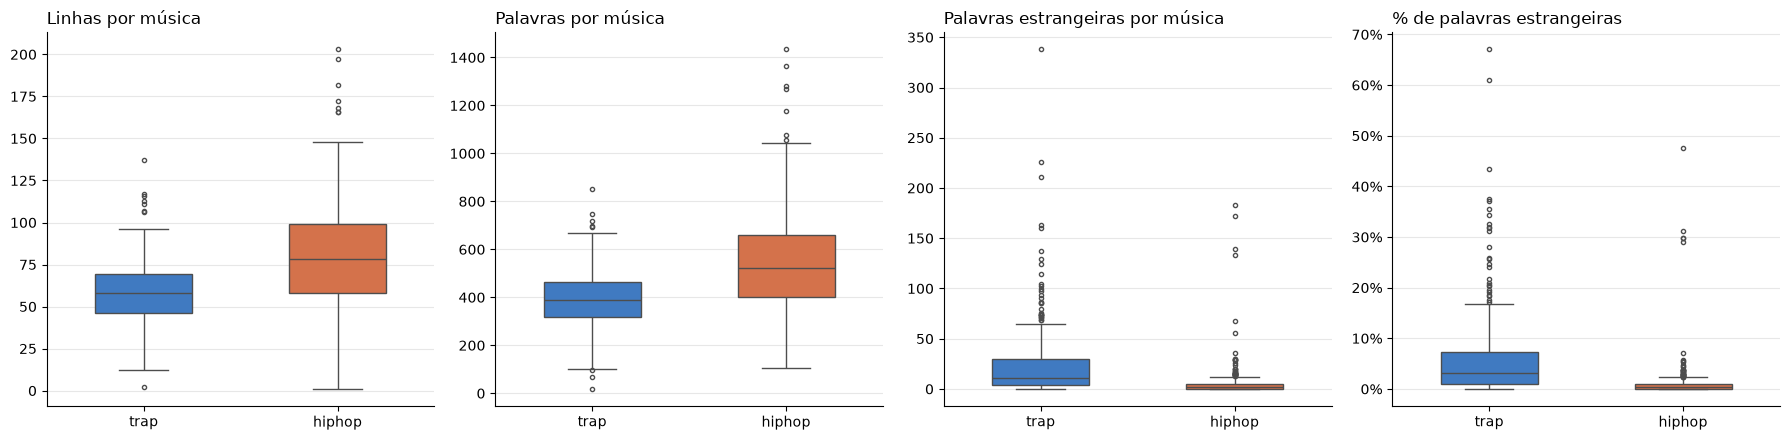

In [140]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
graficos = [("qtd_linhas", "Linhas por música"),
            ("qtd_palavras", "Palavras por música"),
            ("qtd_estrangeiras", "Palavras estrangeiras por música"),
            ("pct_estrangeiras", "% de palavras estrangeiras")]
for ax, (coluna, titulo) in zip(axes, graficos):
    sns.boxplot(data=df_tratado, x="genero", y=coluna, hue="genero", palette=CORES,
                width=0.5, linewidth=1, fliersize=3, legend=False, ax=ax)
    ax.set_title(titulo, loc="left")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(axis="y", alpha=0.3)
    sns.despine(ax=ax)
axes[3].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
plt.show()

### Top 10

- **Palavras mais frequentes**: sem stopwords (português e inglês) e sem interjeições/verbos muito genéricos ("vai", "vou", "quer", "yeah").
- **Palavras estrangeiras mais frequentes** em cada gênero.
- **Artistas que mais usam palavras estrangeiras** (% médio por música).

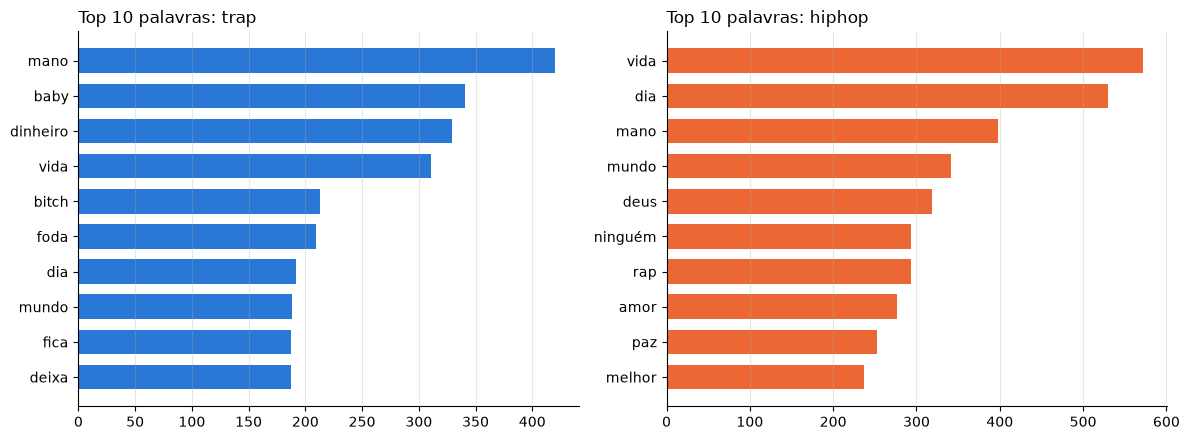

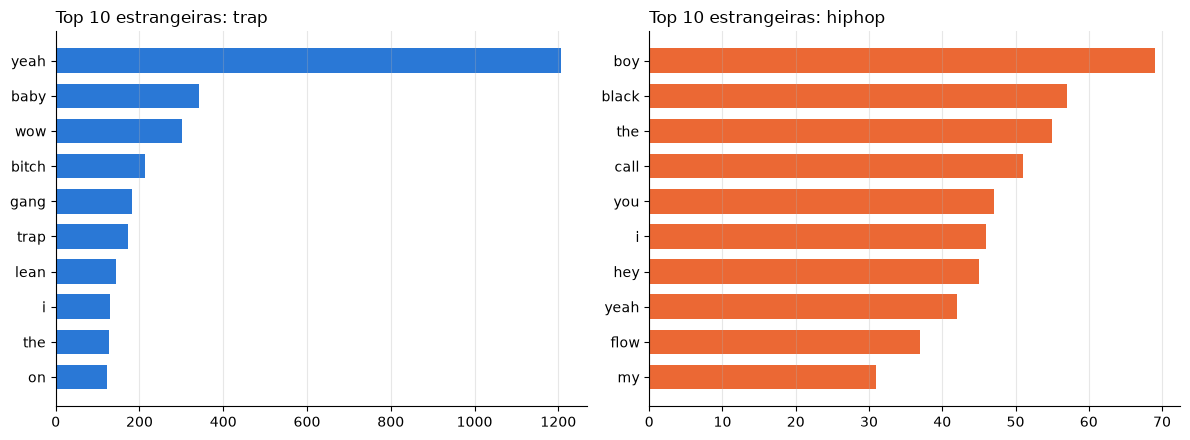

In [141]:
from stop_words import get_stop_words
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

STOPWORDS = set(get_stop_words("portuguese")) | set(ENGLISH_STOP_WORDS) | {
    "vai", "vou", "quer", "quero", "sei", "sabe", "vem", "tão", "pro", "tô", "tá", "cê", "né",
    "ahn", "yeah", "wow", "oh", "ah", "ye", "ay", "hey", "uh", "ooh", "woah", "la", "lá", "ok",
    "tudo", "mim", "nada", "nunca", "sempre", "hoje", "assim", "todo", "toda", "igual", "fala",
    "olha", "ter", "faz", "fazer", "vão", "tem", "ser", "ver", "dá", "sou", "mais", "aqui", "ali",
    "então", "agora", "só", "pode", "posso", "bem", "vez", "nem", "ainda", "cada", "nois", "nóis",
    "nós", "memo", "mesmo", "tipo", "gente", "coisa", "quando", "onde", "porque", "pois",
}


def contar(filtro) -> dict:
    """{gênero: Counter} das palavras que passam no filtro"""
    return {g: Counter(p for ps in palavras[df_tratado["genero"] == g] for p in ps if filtro(p))
            for g in CORES}


def barras_top10(contagens: dict, titulo: str):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, (genero, contagem) in zip(axes, contagens.items()):
        itens = contagem.most_common(10)[::-1]
        ax.barh([p for p, _ in itens], [n for _, n in itens], color=CORES[genero], height=0.7)
        ax.set_title(f"{titulo}: {genero}", loc="left")
        ax.grid(axis="x", alpha=0.3)
        sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()


barras_top10(contar(lambda p: p not in STOPWORDS and len(p) >= 3), "Top 10 palavras")
barras_top10(contar(estrangeira), "Top 10 estrangeiras")

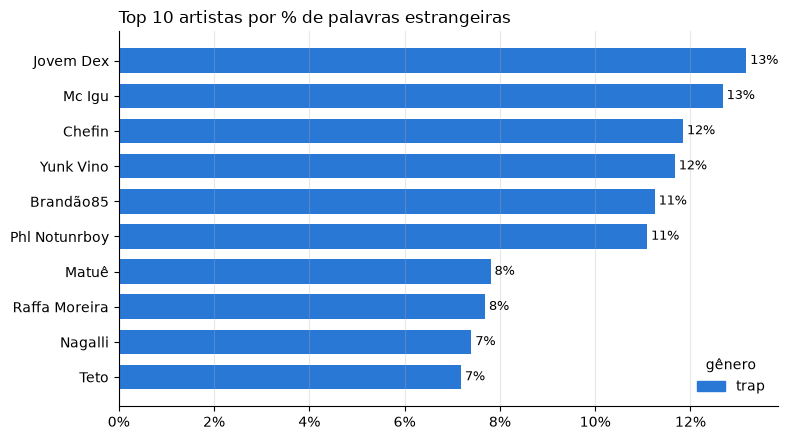

In [142]:
from matplotlib.patches import Patch

top_artistas = (df_tratado.groupby(["artista", "genero"])["pct_estrangeiras"].mean()
                  .reset_index().nlargest(10, "pct_estrangeiras").iloc[::-1])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top_artistas["artista"], top_artistas["pct_estrangeiras"],
        color=top_artistas["genero"].map(CORES), height=0.7)
for y, v in enumerate(top_artistas["pct_estrangeiras"]):
    ax.text(v, y, f" {v:.0%}", va="center", fontsize=9)
ax.legend(handles=[Patch(color=CORES[g], label=g) for g in top_artistas["genero"].unique()[::-1]],
          title="gênero", loc="lower right", frameon=False)
ax.set_title("Top 10 artistas por % de palavras estrangeiras", loc="left")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 6. Clusters

Duas perguntas:
1. **Se agruparmos as letras sem olhar o rótulo, os grupos batem com trap × hip hop?** Rodamos KMeans com k=2 nos embeddings das letras e comparamos com o gênero pelo **ARI** (Adjusted Rand Index: 0 = nada a ver, 1 = idêntico).
2. **Quão separados estão os gêneros no espaço dos embeddings?** O **silhouette** por gênero vai de -1 a 1 (acima de 0 = cada música fica mais perto do próprio gênero que do outro). Comparamos letra e título.

Para enxergar os 1024 números de cada música em 2D usamos o **t-SNE**, que é só para visualização: ele preserva quem está perto de quem, mas distâncias e tamanhos no gráfico não têm significado.

In [143]:
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score

kmeans = KMeans(n_clusters=2, n_init=10, random_state=42).fit(emb_letra)
df_tratado["cluster"] = [f"cluster {c}" for c in kmeans.labels_]

display(pd.crosstab(df_tratado["cluster"], df_tratado["genero"]))
print(f"ARI (cluster x gênero): {adjusted_rand_score(df_tratado['genero'], df_tratado['cluster']):.2f}")
for nome, emb in [("letra", emb_letra), ("título", emb_titulo)]:
    print(f"silhouette por gênero, {nome}: {silhouette_score(emb, df_tratado['genero'], metric='cosine'):.3f}")

genero,hiphop,trap
cluster,,
cluster 0,66,265
cluster 1,285,94


ARI (cluster x gênero): 0.30
silhouette por gênero, letra: 0.055
silhouette por gênero, título: 0.005


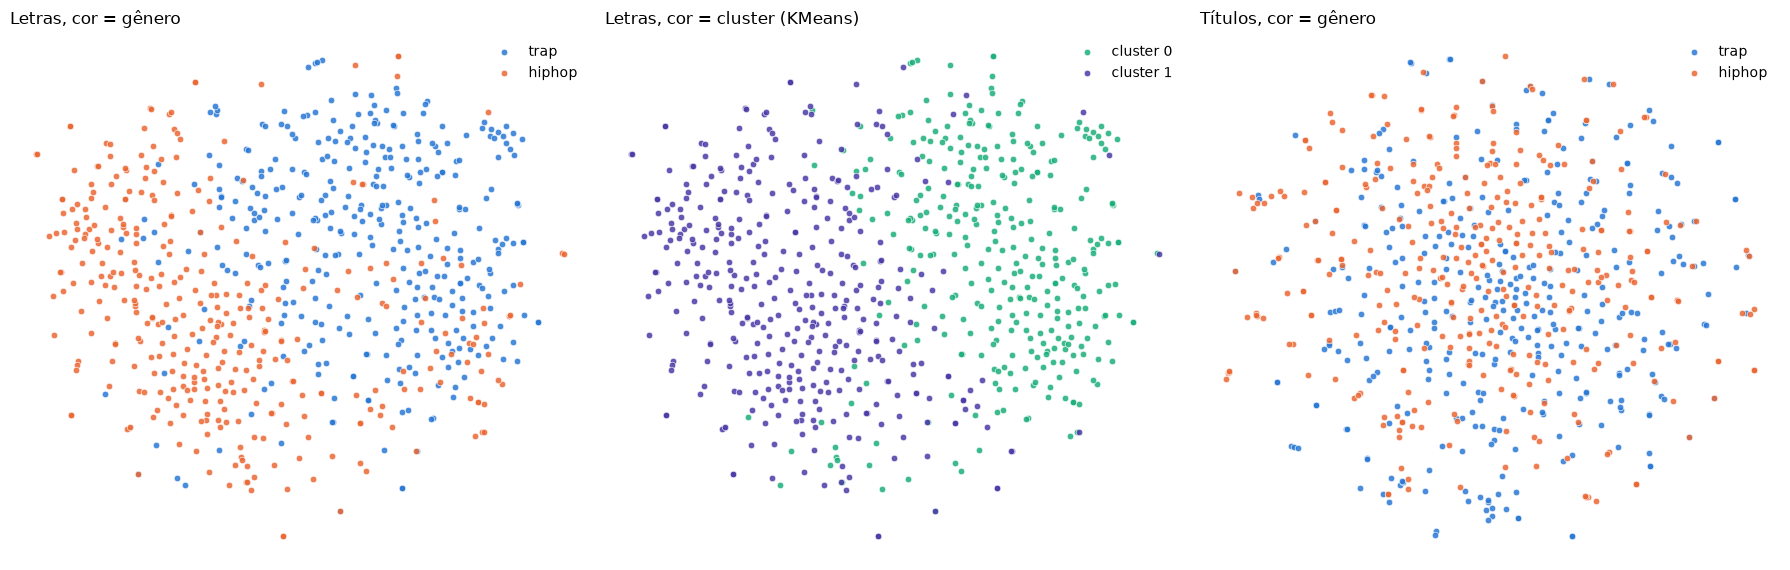

In [144]:
CORES_CLUSTER = {"cluster 0": "#1baf7a", "cluster 1": "#4a3aa7"}  # não repete as cores de gênero

xy_letra = TSNE(n_components=2, metric="cosine", random_state=42).fit_transform(emb_letra)
xy_titulo = TSNE(n_components=2, metric="cosine", random_state=42).fit_transform(emb_titulo)

paineis = [(xy_letra, "genero", CORES, "Letras, cor = gênero"),
           (xy_letra, "cluster", CORES_CLUSTER, "Letras, cor = cluster (KMeans)"),
           (xy_titulo, "genero", CORES, "Títulos, cor = gênero")]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))
for ax, (xy, coluna, cores, titulo) in zip(axes, paineis):
    for grupo, cor in cores.items():
        m = (df_tratado[coluna] == grupo).to_numpy()
        ax.scatter(xy[m, 0], xy[m, 1], s=22, color=cor, label=grupo, alpha=0.85,
                   edgecolors="white", linewidths=0.5)
    ax.set_title(titulo, loc="left")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(frameon=False, loc="best")
    sns.despine(ax=ax, left=True, bottom=True)
plt.tight_layout()
plt.show()

## Separação de Treino e Teste

**O cuidado principal: separar por artista, não por música.** Com o `train_test_split` comum, músicas do Matuê cairiam no treino e no teste ao mesmo tempo. O modelo aprenderia a reconhecer o *jeito do Matuê escrever* e acertaria o teste por isso, não por entender a diferença entre trap e hip hop. A acurácia sairia inflada e não valeria para um artista novo.

Por isso usamos o `StratifiedGroupKFold`:
- **Group**: cada artista fica inteiro de um lado só;
- **Stratified**: mantém a proporção trap × hip hop parecida nos dois lados.

A divisão tem dois níveis:
1. **Teste final** (~20% dos artistas): fica guardado e só é usado **uma vez**, no capítulo de avaliação.
2. **Validação cruzada no treino** (5 partes, também por artista): serve para escolher a regularização de cada modelo e comparar os modelos entre si.

In [145]:
from sklearn.model_selection import StratifiedGroupKFold

y = df_tratado["genero"].to_numpy()
grupos = df_tratado["artista"].to_numpy()

# uma das 5 partes vira o teste final (~20% dos artistas); as outras 4 viram o treino
divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_treino, idx_teste = next(divisor.split(df_tratado, y, grupos))

artistas_treino, artistas_teste = set(grupos[idx_treino]), set(grupos[idx_teste])
assert not artistas_treino & artistas_teste, "artista vazou entre treino e teste!"

# validação cruzada dentro do treino, também separando por artista
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

treino, teste = df_tratado.iloc[idx_treino], df_tratado.iloc[idx_teste]
display(pd.DataFrame({
    "músicas treino": treino["genero"].value_counts(),
    "músicas teste": teste["genero"].value_counts(),
    "artistas treino": treino.groupby("genero")["artista"].nunique(),
    "artistas teste": teste.groupby("genero")["artista"].nunique(),
}))
for genero in CORES:
    print(f"Artistas de {genero} no teste: {', '.join(sorted(teste.loc[teste['genero'] == genero, 'artista'].unique()))}")

,músicas treino,músicas teste,artistas treino,artistas teste
genero,,,,
hiphop,280,71,25,6
trap,289,70,22,5


Artistas de trap no teste: Duzz, Mc Igu, Ryu, the Runner, Sidoka, Yunk Vino
Artistas de hiphop no teste: Haikaiss, Kamau, Marcelo D2, RZO, Rappin' Hood, Sabotage


## Modelos de Comparação

Todos os modelos usam **regressão logística**, então a única coisa que muda entre eles é **a representação da música**. Assim dá para ver o que cada tipo de informação acrescenta:

| modelo | o que ele vê |
|---|---|
| Chute (classe majoritária) | nada: sempre responde a classe mais comum. É o piso. |
| Numéricas | só `qtd_linhas`, `qtd_palavras`, `qtd_estrangeiras` e `pct_estrangeiras` |
| TF-IDF da letra | quais palavras e pares de palavras aparecem (o clássico de texto) |
| Embedding da letra | o vetor de 1024 dimensões do Qwen3 |
| Embedding letra + título | os dois vetores juntos (2048 dimensões) |
| Completo | letra + título + numéricas |

**Detalhes que evitam vazamento de informação do teste:**
- O TF-IDF e o `StandardScaler` ficam **dentro** de um `Pipeline`: a cada rodada da validação cruzada, o vocabulário e as médias são aprendidos só com a parte de treino.
- O embedding não precisa disso: o modelo Qwen3 foi treinado antes e nunca viu estes dados.
- No modelo completo, só as colunas numéricas são padronizadas (vão de 0 a 1.400); o embedding já vem normalizado e passa direto.

**Regularização (`C`):** com mais variáveis (1024 a 2052) do que músicas (~600 no treino), a regularização é o que impede o modelo de decorar o treino. Para cada modelo testamos vários `C` na validação cruzada e ficamos com o melhor.

In [146]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline

GRADE_C = [0.01, 0.1, 1, 10, 100, 1000, 10000]


def logistica():
    return LogisticRegression(max_iter=5000)


numericas = df_tratado[NOVAS].to_numpy()  # qtd_linhas, qtd_palavras, qtd_estrangeiras, pct_estrangeiras
X_completo = np.hstack([emb_letra, emb_titulo, numericas])
colunas_numericas = list(range(X_completo.shape[1] - numericas.shape[1], X_completo.shape[1]))

MODELOS = {  # nome: (X, modelo)
    "Chute (classe majoritária)": (numericas, DummyClassifier(strategy="most_frequent")),
    "Numéricas": (numericas, make_pipeline(StandardScaler(), logistica())),
    "TF-IDF da letra": (df_tratado["letra_limpa"].to_numpy(),
                        make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 2)),
                                      logistica())),
    "Embedding da letra": (emb_letra, logistica()),
    "Embedding letra + título": (np.hstack([emb_letra, emb_titulo]), logistica()),
    "Completo": (X_completo, make_pipeline(
        ColumnTransformer([("num", StandardScaler(), colunas_numericas)], remainder="passthrough"),
        logistica())),
}

resultados, ajustados = [], {}
for nome, (X, modelo) in MODELOS.items():
    param_c = [p for p in modelo.get_params() if p == "C" or p.endswith("__C")]  # o chute não tem C
    grade = {param_c[0]: GRADE_C} if param_c else {}
    busca = GridSearchCV(modelo, grade, cv=cv, scoring="accuracy", n_jobs=-1)
    busca.fit(X[idx_treino], y[idx_treino], groups=grupos[idx_treino])
    ajustados[nome] = busca.best_estimator_  # já retreinado com o treino inteiro
    i = busca.best_index_
    resultados.append({"modelo": nome,
                       "C": busca.best_params_.get(param_c[0]) if param_c else None,
                       "acurácia CV": busca.cv_results_["mean_test_score"][i],
                       "desvio CV": busca.cv_results_["std_test_score"][i]})
    print(f"{nome}: {resultados[-1]['acurácia CV']:.3f} ± {resultados[-1]['desvio CV']:.3f}")

tabela = pd.DataFrame(resultados).set_index("modelo")

Chute (classe majoritária): 0.508 ± 0.013
Numéricas: 0.735 ± 0.024
TF-IDF da letra: 0.919 ± 0.041
Embedding da letra: 0.859 ± 0.070
Embedding letra + título: 0.839 ± 0.066
Completo: 0.868 ± 0.041


## Avaliação

Duas medidas para cada modelo:
- **Acurácia na validação cruzada** (média ± desvio das 5 partes do treino): é ela que usamos para **escolher** o melhor modelo.
- **Acurácia e F1 no teste final**: artistas que nenhum modelo viu. É a estimativa honesta de como o modelo se sai com artistas novos.

O teste tem só uns 11 ou 12 artistas, então um artista difícil a mais ou a menos mexe vários pontos na acurácia. Por isso a escolha é feita pela validação cruzada, não pelo teste: escolher olhando o teste seria "estudar para a prova".

In [147]:
from sklearn.metrics import accuracy_score, f1_score

for nome, (X, _) in MODELOS.items():
    previsto = ajustados[nome].predict(X[idx_teste])
    tabela.loc[nome, "acurácia teste"] = accuracy_score(y[idx_teste], previsto)
    tabela.loc[nome, "F1 macro teste"] = f1_score(y[idx_teste], previsto, average="macro")

escolhido = tabela["acurácia CV"].idxmax()
print(f"Melhor modelo pela validação cruzada: {escolhido}")
tabela.round(3)

Melhor modelo pela validação cruzada: TF-IDF da letra


,C,acurácia CV,desvio CV,acurácia teste,F1 macro teste
modelo,,,,,
Chute (classe majoritária),NaN,0.508,0.013,0.496,0.332
Numéricas,1.0,0.735,0.024,0.809,0.808
TF-IDF da letra,1000.0,0.919,0.041,0.936,0.936
Embedding da letra,100.0,0.859,0.070,0.901,0.900
Embedding letra + título,10.0,0.839,0.066,0.887,0.886
Completo,1000.0,0.868,0.041,0.872,0.872


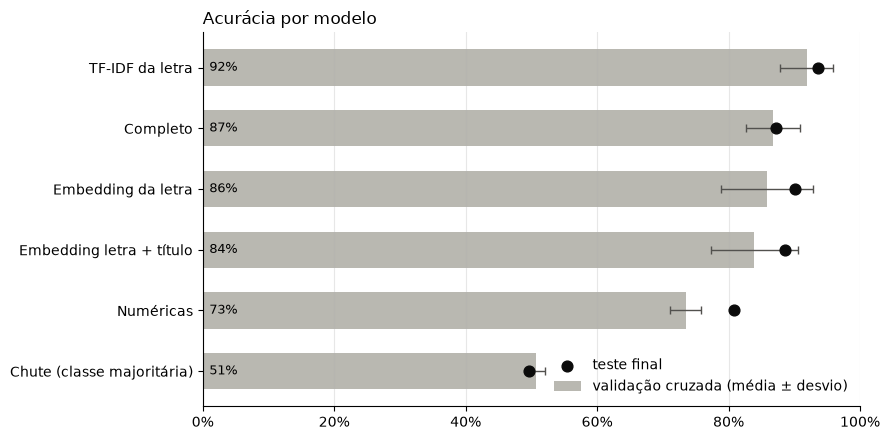

In [148]:
ordem = tabela.sort_values("acurácia CV")
pos = np.arange(len(ordem))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(pos, ordem["acurácia CV"], xerr=ordem["desvio CV"], height=0.6, color="#b9b8b1",
        error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 3}, label="validação cruzada (média ± desvio)")
ax.scatter(ordem["acurácia teste"], pos, s=60, color="#0b0b0b", zorder=3, label="teste final")
for y_pos, v in zip(pos, ordem["acurácia CV"]):
    ax.text(0.01, y_pos, f"{v:.0%}", va="center", fontsize=9)
ax.set_yticks(pos, ordem.index)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Acurácia por modelo", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

In [149]:
X_escolhido, _ = MODELOS[escolhido]
previsto = ajustados[escolhido].predict(X_escolhido[idx_teste])

print(f"{escolhido}, no teste final:\n")
print(classification_report(y[idx_teste], previsto, digits=3))
matriz = pd.crosstab(pd.Series(y[idx_teste], name="real"), pd.Series(previsto, name="previsto"))
display(matriz)

TF-IDF da letra, no teste final:

              precision    recall  f1-score   support

      hiphop      0.931     0.944     0.937        71
        trap      0.942     0.929     0.935        70

    accuracy                          0.936       141
   macro avg      0.936     0.936     0.936       141
weighted avg      0.936     0.936     0.936       141



previsto,hiphop,trap
real,,
hiphop,67,4
trap,5,65


## Análise de Erros

O teste final tem poucas músicas para analisar erros. Então aqui cada música do dataset recebe uma previsão **de um modelo que nunca viu o artista dela** (`cross_val_predict` com 5 partes separadas por artista). Usamos o modelo escolhido na avaliação, com o mesmo `C`.

Perguntas:
1. Algum artista é errado quase sempre? Se sim, talvez o problema seja o **rótulo** (o gênero vem do artista, e tem artista que transita entre os dois), não o modelo.
2. Quais músicas o modelo errou com mais certeza?
3. As músicas erradas têm algo em comum (tamanho, uso de inglês)?
4. Quais palavras mais puxam para cada gênero (pelo TF-IDF, que é interpretável)?

In [150]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

cv_todas = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
proba = cross_val_predict(clone(ajustados[escolhido]), X_escolhido, y, groups=grupos,
                          cv=cv_todas, method="predict_proba")
col_trap = list(ajustados[escolhido].classes_).index("trap")

erros = df_tratado[["artista", "titulo_limpo", "genero", "qtd_palavras", "pct_estrangeiras"]].copy()
erros["prob_trap"] = proba[:, col_trap]
erros["previsto"] = np.where(erros["prob_trap"] >= 0.5, "trap", "hiphop")
erros["acertou"] = erros["previsto"] == erros["genero"]
erros["certeza_no_erro"] = np.where(erros["genero"] == "trap", 1 - erros["prob_trap"], erros["prob_trap"])

print(f"Acurácia com artistas nunca vistos (todas as {len(erros)} músicas): {erros['acertou'].mean():.1%}")
print(erros.groupby("genero")["acertou"].mean().map("{:.1%}".format).to_string())

Acurácia com artistas nunca vistos (todas as 710 músicas): 92.8%
genero
hiphop    92.3%
trap      93.3%


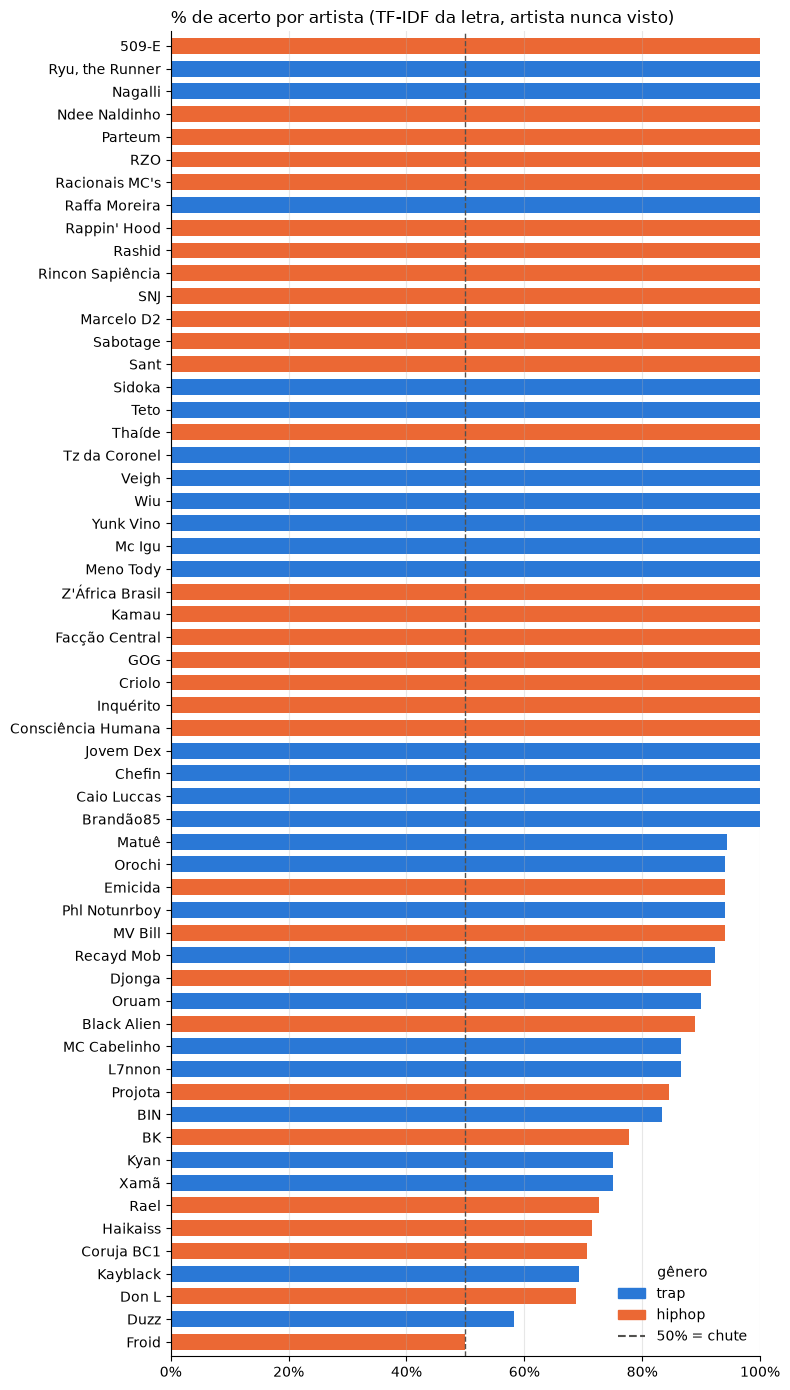

Artistas com menos de 50% de acerto: nenhum


In [151]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

por_artista = (erros.groupby(["artista", "genero"])["acertou"].agg(["mean", "size"])
                     .reset_index().sort_values("mean", ascending=False))

fig, ax = plt.subplots(figsize=(8, 14))
ax.barh(por_artista["artista"], por_artista["mean"], color=por_artista["genero"].map(CORES), height=0.7)
ax.axvline(0.5, color="#52514e", linewidth=1, linestyle="--")
ax.legend(handles=[Patch(color=c, label=g) for g, c in CORES.items()]
                 + [Line2D([], [], color="#52514e", linestyle="--", label="50% = chute")],
          title="gênero", loc="lower right", frameon=False)
ax.set_title(f"% de acerto por artista ({escolhido}, artista nunca visto)", loc="left")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlim(0, 1)
ax.margins(y=0.005)
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

abaixo = por_artista[por_artista["mean"] < 0.5].rename(columns={"mean": "% acerto", "size": "músicas"})
print("Artistas com menos de 50% de acerto:", "nenhum" if abaixo.empty else "")
if not abaixo.empty:
    display(abaixo.round(2))

In [152]:
print("Erros com mais certeza (o modelo tinha convicção e errou):")
display(erros[~erros["acertou"]].nlargest(15, "certeza_no_erro")
        [["artista", "titulo_limpo", "genero", "previsto", "certeza_no_erro", "pct_estrangeiras"]].round(2))

print("Mediana das variáveis, por gênero real e acerto:")
erros.groupby(["genero", "acertou"])[["qtd_palavras", "pct_estrangeiras"]].median().round(3)

Erros com mais certeza (o modelo tinha convicção e errou):


,artista,titulo_limpo,genero,previsto,certeza_no_erro,pct_estrangeiras
654,Coruja BC1,Dopamina,hiphop,trap,0.98,0.00
101,Kayblack,Intro,trap,hiphop,0.98,0.01
721,Haikaiss,Não Sou de Ninguém,hiphop,trap,0.97,0.02
102,Kayblack,Maldito Papel,trap,hiphop,0.97,0.03
495,BK,Só me ligar,hiphop,trap,0.96,0.04
223,L7nnon,Celebrando a Vida - L7NNON Part. John | Podium,trap,hiphop,0.93,0.00
230,L7nnon,FAÇA VALER,trap,hiphop,0.93,0.00
100,Kayblack,Eu Sei Bem,trap,hiphop,0.91,0.00
270,Xamã,BELCHIOR,trap,hiphop,0.91,0.08
665,Coruja BC1,Versão Brasileira,hiphop,trap,0.90,0.02


Mediana das variáveis, por gênero real e acerto:


qtd_palavras  pct_estrangeiras
genero acertou                                
hiphop False           458.0             0.011
       True            529.5             0.003
trap   False           405.0             0.010
       True            389.0             0.035

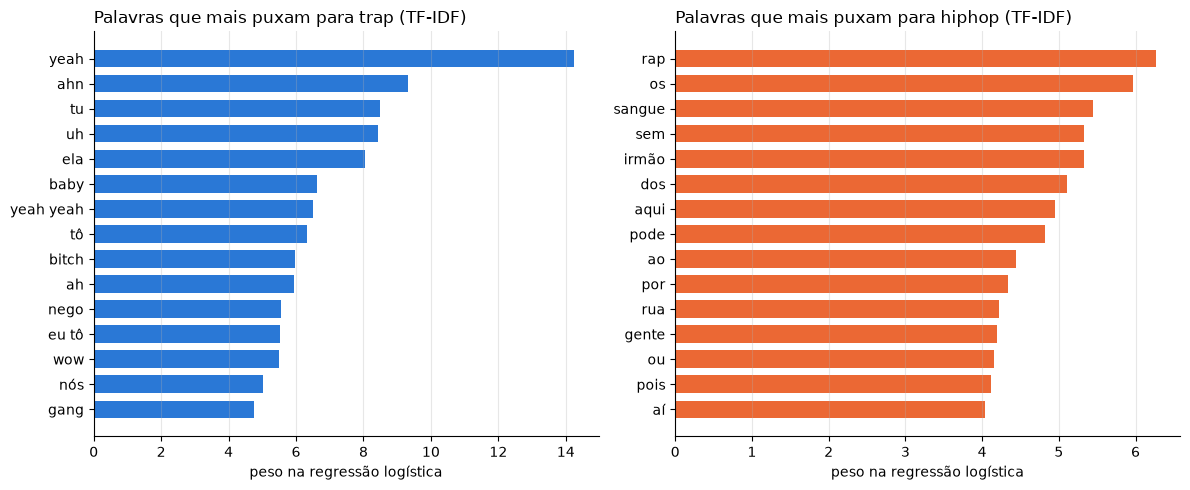

In [153]:
tfidf = ajustados["TF-IDF da letra"]
vocab = tfidf.named_steps["tfidfvectorizer"].get_feature_names_out()
pesos = pd.Series(tfidf.named_steps["logisticregression"].coef_[0], index=vocab)  # positivo = classes_[1]
lado_positivo = tfidf.classes_[1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, genero in zip(axes, CORES):
    top = (pesos if genero == lado_positivo else -pesos).nlargest(15)[::-1]
    ax.barh(top.index, top.values, color=CORES[genero], height=0.7)
    ax.set_title(f"Palavras que mais puxam para {genero} (TF-IDF)", loc="left")
    ax.set_xlabel("peso na regressão logística")
    ax.grid(axis="x", alpha=0.3)
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()

## Conclusão

*Números desta execução (divisão com `random_state=42`), já sem os homônimos Borges e Rapadura: 710 músicas, 359 de trap e 351 de hip hop.*

### Qual abordagem venceu

| modelo | acurácia CV (treino) | acurácia teste |
|---|---|---|
| Chute (classe majoritária) | 50,8% | 49,6% |
| Numéricas | 73,5% ± 2,4 | 80,9% |
| **TF-IDF da letra** | **91,9% ± 4,1** | **93,6%** |
| Embedding da letra | 85,9% ± 7,0 | 90,1% |
| Embedding letra + título | 83,9% ± 6,6 | 88,7% |
| Completo | 86,8% ± 4,1 | 87,2% |

- **O TF-IDF, o método mais clássico, venceu o embedding** na validação cruzada e no teste. A diferença entre trap e hip hop está muito no **vocabulário e na forma**: interjeições, gírias, inglês, conectivos. O TF-IDF enxerga cada palavra exata. O embedding resume o **significado**, e os dois gêneros falam de temas parecidos (vida, mundo, dinheiro, mano), então ele perde parte desse sinal de estilo.
- **O embedding ainda é bom:** 86% na validação cruzada sem nenhuma engenharia de texto, mas oscila mais entre as partes (± 7,0).
- **Só com 4 números** (tamanho da letra e uso de inglês) já dá para acertar 74% a 81%.
- **O título não ajuda.** Juntar o embedding do título deixou o modelo um pouco pior: o título quase não carrega sinal de gênero (silhouette de 0,005 no capítulo de clusters) e dobra o número de variáveis.
- **As variáveis numéricas não somam ao embedding** (o "Completo" ficou no mesmo nível): o embedding já captura tamanho e inglês de outro jeito.
- **Nesta divisão, o teste saiu acima da validação cruzada.** Os 11 artistas sorteados para o teste foram mais fáceis que a média. Com um teste tão pequeno (141 músicas), isso é esperado; por isso a escolha do modelo foi feita pela validação cruzada.

### Limpar os dados valeu mais que trocar de modelo
Tirar os homônimos Borges e Rapadura (32 músicas com o rótulo errado) fez a acurácia do TF-IDF com artistas nunca vistos, medida em todas as músicas, subir de **89,5% para 92,8%**. Os dois tinham sido achados na análise de erros: o modelo "errava" justamente as músicas que não eram de rap. Agora **nenhum artista fica abaixo de 50% de acerto**.

### O que diferencia os gêneros (pesos do TF-IDF)
- **Trap:** ad-libs e interjeições ("yeah", "ahn", "uh", "ah", "wow"), "tô"/"eu tô", "tu", "ela", "baby", "bitch", "nego", "gang". Letras mais curtas e com mais inglês.
- **Hip hop:** "rap" (o rap que fala de rap), "sangue", "irmão", "rua", "gente" e muitos conectivos ("os", "dos", "sem", "por", "pois", "ou"), sinal de letras mais longas e narrativas.

### Onde o modelo ainda erra
Os erros restantes se concentram em artistas que **transitam entre os gêneros**:
- **Froid** (50% de acerto) e **Duzz** (58%);
- trap com letra narrativa, como **Kayblack** ("Intro", "Maldito Papel") e **L7nnon** ("FAÇA VALER"), vira hip hop;
- rap da nova escola, como **Haikaiss**, **Coruja BC1** e **BK**, vira trap;
- **Projota**, em "Rescue Me", que tem 48% de inglês, vira trap.

Aqui o problema é mais o **rótulo por artista** do que o modelo: música a música, esses artistas fazem os dois estilos.

### Limitações
- **O rótulo vem do artista**, não da música.
- **O teste é pequeno** (11 artistas, 141 músicas). Um artista a mais ou a menos muda vários pontos, e uma divisão com outra semente daria outro número.
- **A coleta ainda pode trazer homônimos:** a regra aceita o nome como palavra solta dentro do nome de outro artista. Borges e Rapadura foram achados e retirados, mas um artista novo na lista pode trazer o mesmo problema.
- **A fonte (LRCLIB) tem letras cadastradas erradas**, como a da Britney Spears no Thaíde.

### Próximos passos
1. **Coleta mais rígida:** exigir que o artista buscado seja um dos artistas creditados, não uma palavra solta no nome.
2. **Combinar TF-IDF + embedding** e testar TF-IDF de caracteres (pega grafias como "tô", "cê", "nóis").
3. **Mais artistas por gênero**, para um teste final maior e mais estável.

## Classificando uma música nova

Duas funções para usar o modelo vencedor (TF-IDF da letra):
- `classificar_letra(letra)`: você cola a letra;
- `classificar_musica(artista, titulo)`: busca a letra no LRCLIB e classifica.

As duas mostram o gênero previsto, a probabilidade e as palavras da letra que mais puxaram para cada lado.

**Modelo final:** a avaliação já terminou, então o TF-IDF é retreinado com **todas** as músicas, com o mesmo `C` escolhido na validação cruzada. Mais dados = modelo um pouco melhor para músicas novas.

**Probabilidade calibrada:** com `C=1000` a regressão logística quase não é regularizada e fica confiante demais: responde "100%" para quase tudo. Por isso usamos o `CalibratedClassifierCV`: ele ajusta as probabilidades olhando como o modelo se sai em **artistas que não viu** (as mesmas 5 partes separadas por artista). Assim, "80% trap" passa a significar que o modelo acerta mais ou menos 8 em cada 10 músicas que ele classifica com essa certeza.

**Avisos automáticos:**
- se a música já está no dataset, o modelo já a viu no treino, então acertar não prova nada;
- se a letra quase não tem português, o resultado não é confiável (o modelo só conhece rap em português).

In [154]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV

letras_treino = df_tratado["letra_limpa"].to_numpy()
tfidf_escolhido = ajustados["TF-IDF da letra"]

# probabilidade: 5 modelos, cada um calibrado em artistas que ele não viu
modelo_final = CalibratedClassifierCV(clone(tfidf_escolhido), method="sigmoid",
                                      cv=list(cv_todas.split(letras_treino, y, grupos)))
modelo_final.fit(letras_treino, y)

# explicação: um TF-IDF treinado com todas as músicas, para ver o peso de cada palavra
explicador = clone(tfidf_escolhido).fit(letras_treino, y)
vetorizador_final = explicador.named_steps["tfidfvectorizer"]
pesos_finais = explicador.named_steps["logisticregression"].coef_[0]  # positivo = classes_[1]
termos_finais = vetorizador_final.get_feature_names_out()
letras_no_treino = {normalizar(l)[:200] for l in letras_treino}


def classificar_letra(letra: str, n_palavras: int = 8) -> str:
    """Classifica uma letra como trap ou hiphop e explica o porquê."""
    letra = re.sub(MARCACAO, "", letra).strip()
    if not letra:
        raise ValueError("a letra está vazia")

    proba = dict(zip(modelo_final.classes_, modelo_final.predict_proba([letra])[0]))
    genero = max(proba, key=proba.get)
    print(f"→ {genero.upper()} ({proba[genero]:.0%}) | trap {proba['trap']:.0%} · hiphop {proba['hiphop']:.0%}")

    if normalizar(letra)[:200] in letras_no_treino:
        print("  ⚠️ essa música está no dataset: o modelo já a viu no treino, então não é uma previsão de verdade")
    if proporcao_linhas_pt(letra) < MIN_LINHAS_PT:
        print("  ⚠️ a letra quase não tem português: o modelo foi treinado só com rap em português")

    # contribuição de cada palavra = valor no TF-IDF desta letra x peso aprendido pelo modelo
    contrib = vetorizador_final.transform([letra]).multiply(pesos_finais).tocsr()
    ordem = contrib.data.argsort()
    lado_positivo, lado_negativo = explicador.classes_[1], explicador.classes_[0]
    pro_positivo = [termos_finais[contrib.indices[i]] for i in ordem[::-1][:n_palavras] if contrib.data[i] > 0]
    pro_negativo = [termos_finais[contrib.indices[i]] for i in ordem[:n_palavras] if contrib.data[i] < 0]
    print(f"  puxaram para {lado_positivo}: {', '.join(pro_positivo) or '-'}")
    print(f"  puxaram para {lado_negativo}: {', '.join(pro_negativo) or '-'}")
    return genero


def buscar_letra(artista: str, titulo: str):
    """(nome encontrado, letra) no LRCLIB, ou None. Só aceita resultado do artista pedido."""
    padrao = re.compile(rf"\b{re.escape(normalizar(artista))}\b")
    nome = f"{artista} - {titulo}"
    resultados = (buscar_artista(nome, params={"artist_name": artista, "track_name": titulo})
                  or buscar_artista(nome, params={"q": f"{artista} {titulo}"}))  # aproximada: acento, "feat." etc.
    for item in resultados:
        if item.get("plainLyrics") and padrao.search(normalizar(item.get("artistName") or "")):
            return f"{item['artistName']} - {item['trackName']}", item["plainLyrics"]
    return None


def classificar_musica(artista: str, titulo: str):
    """Busca a letra no LRCLIB e classifica. Devolve o gênero, ou None se não achar a letra."""
    achada = buscar_letra(artista, titulo)
    if achada is None:
        print(f"Letra de '{artista} - {titulo}' não encontrada no LRCLIB.")
        return None
    nome, letra = achada
    print(f"🎵 {nome}")
    return classificar_letra(letra)

### Exemplos

Músicas de artistas que **não estão** no dataset, uma que **está** (para ver o aviso) e uma letra colada direto.

In [155]:
classificar_musica("De", "BIG MONEY")
print()
classificar_musica("Ryu, The Runner", "SWAG EVERY DAY")
print()
classificar_musica("LEALL", "Medo de quase nada")
print()
classificar_musica("Racionais MC's", "Fórmula Mágica da Paz")  # está no dataset: deve mostrar o aviso
print()
# letra colada direto (texto de exemplo)
classificar_letra("""
Yeah, yeah, ahn
Acordei tarde, o drip tá no pescoço
Ela me liga, baby, hoje eu tô no corre
Gang no carro, o som no talo, tô de lean
Money na mão, bitch, ninguém mais segura a gente
""")

Letra de 'De - BIG MONEY' não encontrada no LRCLIB.

🎵 Ryu, The Runner - SWAG EVERY DAY
→ TRAP (99%) | trap 99% · hiphop 1%
  puxaram para trap: wow, yeah, fumando, uh, fumando um, swag, eu sou, nóis
  puxaram para hiphop: ou, minas, to, como, vida, estou, carros, pau

🎵 LEALL - Medo de Quase Nada
→ HIPHOP (51%) | trap 49% · hiphop 51%
  puxaram para trap: yeah, tô, eu tô, hoje, eu, nego, hoje eu, ela
  puxaram para hiphop: homem, quase nada, medo, olho, cada, fora, saber, rua

🎵 Racionais MC’s - Fórmula mágica da paz
→ HIPHOP (100%) | trap 0% · hiphop 100%
  ⚠️ essa música está no dataset: o modelo já a viu no treino, então não é uma previsão de verdade
  puxaram para trap: tô, eu tô, eu, minha, eu sou, tá, mano, mas eu
  puxaram para hiphop: aí, sangue, aqui, ladrão, os, lei, sem, paz

→ TRAP (100%) | trap 100% · hiphop 0%
  puxaram para trap: yeah, ahn, tô, yeah yeah, baby, bitch, gang, lean
  puxaram para hiphop: gente, mão, som, ninguém, acordei, na mão, liga, segura


'trap'

In [162]:
classificar_musica("Yunk Vino", "Leans pt 2")
print()

🎵 Yunk Vino - Leans, Pt. 2
→ TRAP (100%) | trap 100% · hiphop 0%
  ⚠️ essa música está no dataset: o modelo já a viu no treino, então não é uma previsão de verdade
  puxaram para trap: yeah, baby, ye, ah, lean, wow, essas, uh
  puxaram para hiphop: aqui, sem, bom, ta, em, começou, de mim, por aqui

